# 08 · Extra metrics for the paper (Part A)

**Nothing is retrained.** This notebook reads the probability files that the six modality notebooks already saved
(`probs_<modality>.csv`, `info_<modality>.json`, `split_shared.csv`, `meth_info.csv`) and computes the metrics a
journal reviewer will ask for:

| Group | Metrics |
|---|---|
| Classification | macro-F1, weighted F1, accuracy, balanced accuracy, Cohen's κ, MCC, top-2 accuracy, per-class sensitivity / specificity |
| Ranking | ROC-AUC and PR-AUC per class (one-vs-rest) + macro averages |
| Probability quality | log-loss, Brier score, expected calibration error (ECE) + reliability diagrams |
| Robustness | LGG-only macro-F1, GBM recall by methylation platform, per-hospital scores, CV-to-test gap, F1 vs number of available modalities |
| Statistics | bootstrap 95 % CIs, paired-bootstrap p-values, **Holm and Bonferroni** correction for the quantum-vs-classical tests |
| Efficiency | trainable parameters of each VQC vs the classical models on the same patients |

**Fusion models.** If the file `fusion_probs_all_methods.csv` is attached (made by the one export cell added at the end
of the fusion notebook), every fusion method is analysed exactly as in the paper, including stacking and the meta-VQC.
If it is missing, this notebook rebuilds the four pooling fusions itself (mean, reliability-weighted, learned weights
global / per class) from the modality probabilities and checks that it reproduces the reported scores.

**Inputs:** attach the `glioma-modality-outputs` dataset (and the fusion notebook output, if you made the export file).
Runtime ≈ 3–6 min on a Kaggle CPU.

In [1]:
# ============================================================
# 0. IMPORTS AND CONFIGURATION
# ============================================================
import os, glob, json, warnings, time
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from sklearn.metrics import (f1_score, accuracy_score, balanced_accuracy_score, cohen_kappa_score, matthews_corrcoef,
                             roc_auc_score, average_precision_score, log_loss, confusion_matrix)
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 60)

INPUT_ROOT = os.environ.get("PARTA_INPUT", "/kaggle/input" if os.path.isdir("/kaggle/input") else ".")
OUTPUT_DIR = os.path.join(os.environ.get("OUTPUT_DIR", "/kaggle/working" if os.path.isdir("/kaggle/working") else "."),
                          "partA")
os.makedirs(OUTPUT_DIR, exist_ok=True)

MODALITIES = ["proteomics", "methylation", "gene_expression", "mirna", "snv", "cnv"]
SHORT_M = {"proteomics": "PROT", "methylation": "METH", "gene_expression": "GE", "mirna": "miRNA", "snv": "SNV", "cnv": "CNV"}
CLASSES = ["astrocytoma", "glioblastoma", "mixed_glioma", "oligodendroglioma"]
SHORT = ["Astro", "GBM", "Mixed", "Oligo"]
K = len(CLASSES); GBM_I = 1; LGG_I = [0, 2, 3]
FINAL = ("VQC", "Learned weights (global)")          # final model in the report
N_BOOT, SEED = 2000, 42                              # identical to the fusion notebook
EPS = 1e-6
# expected values from the fusion notebook, used only to check that this notebook reproduces them
EXPECTED_TEST_F1 = {("VQC", "Learned weights (global)"): 0.698, ("LR", "Learned weights (global)"): 0.706,
                    ("VQC", "Reliability-weighted"): 0.730, ("LR", "Mean"): 0.672}


def find(name):
    hits = sorted(glob.glob(os.path.join(INPUT_ROOT, "**", name), recursive=True))
    return hits[0] if hits else None


print("Input root:", INPUT_ROOT, "| output:", OUTPUT_DIR)

Input root: /kaggle/input | output: /kaggle/working/partA


In [2]:
# ============================================================
# 1. LOAD THE SAVED FILES
# ============================================================
paths = {m: find(f"probs_{m}.csv") for m in MODALITIES}
missing = [m for m, p in paths.items() if p is None]
assert not missing, f"probs file not found for {missing}: attach the glioma-modality-outputs dataset"
INFO = {m: json.load(open(os.path.join(os.path.dirname(paths[m]), f"info_{m}.json"))) for m in MODALITIES}
hashes = {m: INFO[m]["split_hash"] for m in MODALITIES}
assert len(set(hashes.values())) == 1, f"different splits: {hashes}"

cohort = pd.read_csv(os.path.join(os.path.dirname(paths["proteomics"]), "split_shared.csv"), index_col=0)
cohort.index = cohort.index.astype(str)
cohort = cohort.rename(columns={f"has_{m}": m for m in MODALITIES})
for m in MODALITIES:
    cohort[m] = cohort[m].astype(bool)
mi = find("meth_info.csv")
plat = pd.read_csv(mi, index_col=0)["platform"] if mi else pd.Series(dtype=str)
plat.index = plat.index.astype(str)
cohort["platform"] = plat.reindex(cohort.index).fillna("none")
cohort["n_mod"] = cohort[MODALITIES].sum(axis=1)
TRAIN = cohort.index[cohort["split"] == "train"]; TEST = cohort.index[cohort["split"] == "test"]
y_of = lambda ids: np.array([CLASSES.index(c) for c in cohort.loc[ids, "subtype"]])

PROBS = {}       # PROBS[(modality, model, set)] = DataFrame patients x 4
for m in MODALITIES:
    P = pd.read_csv(paths[m]); P["patient"] = P["patient"].astype(str)
    for (model, st), d in P.groupby(["model", "set"]):
        if model == "LR_LGG":
            continue
        PROBS[(m, model, st)] = d.set_index("patient")[CLASSES].astype(float)

fus_path = find("fusion_probs_all_methods.csv")
FUS = None
if fus_path:
    FUS = pd.read_csv(fus_path); FUS["patient"] = FUS["patient"].astype(str)
print(f"Split {next(iter(hashes.values()))} | train {len(TRAIN)} | test {len(TEST)}")
print("Fusion export:", fus_path or "not found -> pooling fusions will be rebuilt here (section 3)")

Split f3ea2f6bb5ee | train 315 | test 124
Fusion export: /kaggle/input/datasets/nirupamas1746/fusion-probs-all-methods/fusion_probs_all_methods.csv


In [3]:
# ============================================================
# 2. METRIC FUNCTIONS
# ============================================================
def macro_f1(y, pred, labels=range(K)):
    return f1_score(y, pred, labels=list(labels), average="macro", zero_division=0)


def ece_score(y, P, n_bins=10):
    conf, pred = P.max(1), P.argmax(1)
    bins = np.linspace(0, 1, n_bins + 1); e = 0.0
    for lo, hi in zip(bins[:-1], bins[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            e += m.mean() * abs((pred[m] == y[m]).mean() - conf[m].mean())
    return e


def all_metrics(y, P, is_prob=True):
    # y: int labels (n,), P: (n, 4) probabilities (or scores if is_prob=False)
    pred = P.argmax(1); r = {}
    r["n"] = len(y)
    r["macro_f1"] = macro_f1(y, pred)
    r["weighted_f1"] = f1_score(y, pred, labels=range(K), average="weighted", zero_division=0)
    r["accuracy"] = accuracy_score(y, pred)
    r["balanced_acc"] = balanced_accuracy_score(y, pred)
    r["kappa"] = cohen_kappa_score(y, pred, labels=range(K))
    r["mcc"] = matthews_corrcoef(y, pred)
    r["top2_acc"] = np.mean([yi in np.argsort(-p)[:2] for yi, p in zip(y, P)])
    cm = confusion_matrix(y, pred, labels=range(K))
    for c, s in enumerate(SHORT):
        tp = cm[c, c]; fn = cm[c].sum() - tp; fp = cm[:, c].sum() - tp; tn = cm.sum() - tp - fn - fp
        r[f"sens_{s}"] = tp / (tp + fn) if tp + fn else np.nan
        r[f"spec_{s}"] = tn / (tn + fp) if tn + fp else np.nan
    lg = y != GBM_I
    r["lgg_macro_f1"] = macro_f1(y[lg], pred[lg], labels=LGG_I)
    aucs, aps = [], []
    for c, s in enumerate(SHORT):
        yc = (y == c).astype(int)
        if 0 < yc.sum() < len(yc):
            aucs.append(roc_auc_score(yc, P[:, c])); aps.append(average_precision_score(yc, P[:, c]))
        else:
            aucs.append(np.nan); aps.append(np.nan)
        r[f"auc_{s}"], r[f"prauc_{s}"] = aucs[-1], aps[-1]
    r["macro_auc"], r["macro_prauc"] = np.nanmean(aucs), np.nanmean(aps)
    if is_prob:
        Q = np.clip(P, EPS, 1); Q = Q / Q.sum(1, keepdims=True)
        r["log_loss"] = log_loss(y, Q, labels=range(K))
        r["brier"] = np.mean(((Q - np.eye(K)[y]) ** 2).sum(1))
        r["ece"] = ece_score(y, Q)
    else:
        r["log_loss"] = r["brier"] = r["ece"] = np.nan
    return r


def boot_idx(n, b=N_BOOT, seed=SEED):
    rng = np.random.default_rng(seed)
    return [rng.integers(0, n, n) for _ in range(b)]


def boot_ci(y, P, fn, b=N_BOOT):
    v = [fn(y[i], P[i]) for i in boot_idx(len(y), b)]
    return np.nanpercentile(v, [2.5, 97.5])


def paired_test(y, pa, pb, b=N_BOOT):
    # paired bootstrap on macro-F1 of two prediction vectors; two-sided p-value from the bootstrap distribution
    d = np.array([macro_f1(y[i], pa[i]) - macro_f1(y[i], pb[i]) for i in boot_idx(len(y), b)])
    p = min(1.0, 2 * min((d <= 0).mean(), (d >= 0).mean()))
    return d.mean(), np.percentile(d, [2.5, 97.5]), max(p, 1.0 / b)


def holm(pvals):
    p = np.asarray(pvals, float); o = np.argsort(p); m = len(p); adj = np.empty(m); run = 0.0
    for r, i in enumerate(o):
        run = max(run, (m - r) * p[i]); adj[i] = min(1.0, run)
    return adj


print("metric functions ready")

metric functions ready


In [4]:
# ============================================================
# 3. FUSION PROBABILITIES (from the fusion export, or rebuilt here)
# ============================================================
FUSION = {}            # FUSION[(base, method, set)] = DataFrame patients x 4
NOT_PROB = set()       # methods whose output is not a calibrated probability (hierarchical uses a hard GBM rule)

if FUS is not None:
    for (b, meth, st), d in FUS.groupby(["base", "method", "set"]):
        FUSION[(b, meth, st)] = d.set_index("patient")[CLASSES].astype(float)
        if meth.startswith("Hierarchical"):
            NOT_PROB.add((b, meth))
else:
    def meta_arrays(fam, ids, st):
        P, M = {}, {}
        for m in MODALITIES:
            key = (m, fam, st)
            d = PROBS[key].reindex(ids) if key in PROBS else pd.DataFrame(index=ids, columns=CLASSES, dtype=float)
            M[m] = d.notna().all(axis=1).values
            P[m] = np.where(M[m][:, None], d.fillna(1.0 / K).values, 1.0 / K)
        return P, M

    sub = lambda D, i: {k: v[i] for k, v in D.items()}
    cw = lambda y: (len(y) / (K * np.maximum(np.bincount(y, minlength=K), 1)))[y]

    class Mean:
        def fit(self, y, P, M): return self
        def proba(self, P, M):
            num = sum(P[m] * M[m][:, None] for m in MODALITIES); den = sum(M[m][:, None].astype(float) for m in MODALITIES)
            return num / np.maximum(den, 1)

    class Reliability:
        def fit(self, y, P, M):
            self.w = {m: np.maximum(f1_score(y[M[m]], P[m][M[m]].argmax(1), labels=range(K), average=None,
                                             zero_division=0), 1e-3) for m in MODALITIES}
            return self
        def proba(self, P, M):
            num = sum(P[m] * self.w[m] * M[m][:, None] for m in MODALITIES)
            den = sum(self.w[m] * M[m][:, None] for m in MODALITIES)
            q = num / np.maximum(den, 1e-9); return q / q.sum(1, keepdims=True)

    class LearnedWeights:   # identical to the fusion notebook
        def __init__(self, per_class=False):
            self.pc = per_class; self.l2 = 0.1 if per_class else 0.05
        def _z(self, th, L, Mk):
            nm = len(MODALITIES)
            W = np.exp(th[:nm * K].reshape(nm, K)) if self.pc else np.repeat(np.exp(th[:nm])[:, None], K, 1)
            return np.einsum("imk,mk->ik", L * Mk[:, :, None], W) + th[-K:]
        def fit(self, y, P, M):
            L = np.stack([np.log(P[m] + EPS) for m in MODALITIES], 1); Mk = np.stack([M[m] for m in MODALITIES], 1).astype(float)
            sw = cw(y); Y = np.eye(K)[y]; nw = len(MODALITIES) * (K if self.pc else 1)
            def obj(th):
                z = self._z(th, L, Mk); z = z - z.max(1, keepdims=True); lp = z - np.log(np.exp(z).sum(1, keepdims=True))
                return -(sw * (Y * lp).sum(1)).sum() / sw.sum() + self.l2 * np.sum(th[:nw] ** 2)
            self.th = minimize(obj, np.zeros(nw + K), method="L-BFGS-B").x; return self
        def proba(self, P, M):
            L = np.stack([np.log(P[m] + EPS) for m in MODALITIES], 1); Mk = np.stack([M[m] for m in MODALITIES], 1).astype(float)
            z = self._z(self.th, L, Mk); z = z - z.max(1, keepdims=True); e = np.exp(z); return e / e.sum(1, keepdims=True)

    METHODS = {"Mean": Mean, "Reliability-weighted": Reliability,
               "Learned weights (global)": lambda: LearnedWeights(False),
               "Learned weights (per class)": lambda: LearnedWeights(True)}
    y_tr = y_of(TRAIN); fold = cohort.loc[TRAIN, "fold"].values
    for fam in ["LR", "VQC"]:
        Ptr, Mtr = meta_arrays(fam, TRAIN, "oof"); Pte, Mte = meta_arrays(fam, TEST, "test")
        for name, make in METHODS.items():
            cv = np.zeros((len(TRAIN), K))
            for k in sorted(set(fold)):
                a, b = np.where(fold != k)[0], np.where(fold == k)[0]
                cv[b] = make().fit(y_tr[a], sub(Ptr, a), sub(Mtr, a)).proba(sub(Ptr, b), sub(Mtr, b))
            FUSION[(fam, name, "cv")] = pd.DataFrame(cv, index=TRAIN, columns=CLASSES)
            FUSION[(fam, name, "test")] = pd.DataFrame(make().fit(y_tr, Ptr, Mtr).proba(Pte, Mte), index=TEST, columns=CLASSES)

y_te = y_of(TEST)
print("Fusion methods available:", sorted({(b, m) for b, m, s in FUSION}))
print("\nReproduction check (test macro-F1, this notebook vs the paper):")
for key, exp in EXPECTED_TEST_F1.items():
    if (*key, "test") in FUSION:
        got = macro_f1(y_te, FUSION[(*key, "test")].loc[TEST].values.argmax(1))
        print(f"  {key[1]:28s} [{key[0]} base]  {got:.3f}  (paper {exp:.3f})  {'OK' if abs(got - exp) < 0.0015 else 'CHECK'}")

Fusion methods available: [('LR', 'CNV only'), ('LR', 'GE only'), ('LR', 'Hierarchical (learned weights)'), ('LR', 'Hierarchical (mean)'), ('LR', 'Learned weights (global)'), ('LR', 'Learned weights (per class)'), ('LR', 'METH only'), ('LR', 'Mean'), ('LR', 'Meta-LR (same 8 inputs as meta-VQC)'), ('LR', 'Meta-VQC (8 qubits)'), ('LR', 'PROT only'), ('LR', 'Reliability-weighted'), ('LR', 'SNV only'), ('LR', 'Stacking LR'), ('LR', 'miRNA only'), ('VQC', 'CNV only'), ('VQC', 'GE only'), ('VQC', 'Learned weights (global)'), ('VQC', 'Learned weights (per class)'), ('VQC', 'METH only'), ('VQC', 'Mean'), ('VQC', 'Meta-LR (same 8 inputs as meta-VQC)'), ('VQC', 'Meta-VQC (8 qubits)'), ('VQC', 'PROT only'), ('VQC', 'Reliability-weighted'), ('VQC', 'SNV only'), ('VQC', 'Stacking LR'), ('VQC', 'miRNA only')]

Reproduction check (test macro-F1, this notebook vs the paper):
  Learned weights (global)     [VQC base]  0.698  (paper 0.698)  OK
  Learned weights (global)     [LR base]  0.706  (paper 0.70

In [5]:
# ============================================================
# 4. TABLE A1 — ALL CLASSIFICATION, RANKING AND PROBABILITY METRICS ON THE 7 HELD-OUT HOSPITALS
# single modalities: scored on the test patients that have the modality; fusion: all 124 test patients
# ============================================================
rows = []
for m in MODALITIES:
    for model in ["VQC", "LRm", "LR"]:
        d = PROBS[(m, model, "test")]
        r = all_metrics(y_of(d.index), d.values)
        rows.append({"level": "modality", "modality": SHORT_M[m], "model": model, **r})
for (b, meth, st), d in FUSION.items():
    if st != "test" or meth.endswith(" only"):
        continue
    r = all_metrics(y_of(d.index), d.loc[TEST].values, is_prob=(b, meth) not in NOT_PROB)
    rows.append({"level": "fusion", "modality": "fusion", "model": f"{meth} [{b}]", **r})
A1 = pd.DataFrame(rows)
A1.to_csv(os.path.join(OUTPUT_DIR, "A1_all_metrics_test.csv"), index=False)

main_cols = ["level", "modality", "model", "n", "macro_f1", "balanced_acc", "kappa", "mcc", "top2_acc",
             "macro_auc", "macro_prauc", "log_loss", "brier", "ece", "lgg_macro_f1"]
print("Table A1 (main columns). LRm = logistic regression on exactly the VQC's features; LR = tuned logistic regression.")
print("Probability metrics are blank for hierarchical fusion (its GBM step is a hard rule, not a probability).")
display(A1[main_cols].round(3))
print("\nPer-class ROC-AUC / PR-AUC / sensitivity / specificity are in A1_all_metrics_test.csv")

Table A1 (main columns). LRm = logistic regression on exactly the VQC's features; LR = tuned logistic regression.
Probability metrics are blank for hierarchical fusion (its GBM step is a hard rule, not a probability).


,level,modality,model,n,macro_f1,balanced_acc,kappa,mcc,top2_acc,macro_auc,macro_prauc,log_loss,brier,ece,lgg_macro_f1
0,modality,PROT,VQC,95,0.521,0.601,0.346,0.359,0.800,0.791,0.597,1.109,0.630,0.136,0.472
1,modality,PROT,LRm,95,0.530,0.598,0.353,0.362,0.789,0.786,0.626,1.217,0.634,0.151,0.501
2,modality,PROT,LR,95,0.584,0.653,0.418,0.430,0.800,0.818,0.663,1.031,0.582,0.098,0.535
3,modality,METH,VQC,123,0.561,0.578,0.419,0.423,0.870,0.845,0.650,0.851,0.480,0.111,0.451
4,modality,METH,LRm,123,0.575,0.602,0.435,0.443,0.862,0.845,0.653,0.836,0.483,0.038,0.477
5,modality,METH,LR,123,0.705,0.713,0.595,0.603,0.902,0.885,0.772,0.763,0.415,0.087,0.651
6,modality,GE,VQC,123,0.670,0.674,0.542,0.544,0.821,0.845,0.685,0.887,0.478,0.069,0.596
7,modality,GE,LRm,123,0.668,0.685,0.543,0.552,0.886,0.854,0.696,0.848,0.470,0.100,0.572
8,modality,GE,LR,123,0.588,0.594,0.421,0.422,0.870,0.833,0.628,0.852,0.497,0.143,0.451
9,modality,miRNA,VQC,111,0.614,0.642,0.430,0.438,0.856,0.816,0.658,0.857,0.513,0.105,0.485



Per-class ROC-AUC / PR-AUC / sensitivity / specificity are in A1_all_metrics_test.csv


In [6]:
# ============================================================
# 5. TABLE A2 — 95 % BOOTSTRAP CIs FOR THE KEY MODELS (2,000 resamples, same seed as the fusion notebook)
# ============================================================
def key_models():
    out = []
    for fam in ["VQC", "LR"]:
        for meth in ["Learned weights (global)", "Reliability-weighted", "Mean"]:
            if (fam, meth, "test") in FUSION:
                out.append((f"{meth} [{fam}]", FUSION[(fam, meth, "test")].loc[TEST]))
    out.append(("miRNA only, LR (best single)", PROBS[("mirna", "LR", "test")]))
    out.append(("miRNA only, VQC", PROBS[("mirna", "VQC", "test")]))
    return out


f_auc = lambda yy, PP: np.nanmean([roc_auc_score((yy == c).astype(int), PP[:, c]) if 0 < (yy == c).sum() < len(yy)
                                   else np.nan for c in range(K)])
rows = []
for name, d in key_models():
    yy, PP = y_of(d.index), d.values
    r = {"model": name, "n": len(yy)}
    for lab, fn in [("macro_f1", lambda a, b: macro_f1(a, b.argmax(1))), ("macro_auc", f_auc),
                    ("mcc", lambda a, b: matthews_corrcoef(a, b.argmax(1))),
                    ("kappa", lambda a, b: cohen_kappa_score(a, b.argmax(1), labels=range(K)))]:
        lo, hi = boot_ci(yy, PP, fn)
        r[lab] = f"{fn(yy, PP):.3f} ({lo:.3f}–{hi:.3f})"
    rows.append(r)
A2 = pd.DataFrame(rows); A2.to_csv(os.path.join(OUTPUT_DIR, "A2_key_models_ci.csv"), index=False)
display(A2)

,model,n,macro_f1,macro_auc,mcc,kappa
0,Learned weights (global) [VQC],124,0.698 (0.618–0.769),0.883 (0.837–0.924),0.594 (0.483–0.698),0.590 (0.478–0.695)
1,Reliability-weighted [VQC],124,0.730 (0.650–0.799),0.873 (0.827–0.915),0.637 (0.528–0.738),0.632 (0.519–0.732)
2,Mean [VQC],124,0.715 (0.634–0.786),0.870 (0.825–0.911),0.629 (0.522–0.726),0.622 (0.515–0.719)
3,Learned weights (global) [LR],124,0.706 (0.628–0.778),0.890 (0.846–0.928),0.591 (0.475–0.700),0.588 (0.469–0.694)
4,Reliability-weighted [LR],124,0.677 (0.593–0.748),0.879 (0.834–0.918),0.563 (0.447–0.669),0.556 (0.438–0.662)
5,Mean [LR],124,0.672 (0.587–0.746),0.877 (0.832–0.916),0.565 (0.452–0.670),0.557 (0.441–0.662)
6,"miRNA only, LR (best single)",111,0.694 (0.614–0.763),0.852 (0.801–0.899),0.556 (0.432–0.666),0.550 (0.423–0.659)
7,"miRNA only, VQC",111,0.614 (0.537–0.682),0.816 (0.760–0.865),0.438 (0.301–0.560),0.430 (0.292–0.549)


In [7]:
# ============================================================
# 6. TABLE A3 — ROBUSTNESS: CV-TO-TEST GAP, LGG-ONLY, GBM RECALL BY METHYLATION PLATFORM
# ============================================================
def gbm_recall(ids, pred, p):
    msk = (cohort.loc[ids, "subtype"].values == "glioblastoma") & (cohort.loc[ids, "platform"].values == p)
    return (float((pred[msk] == GBM_I).mean()), int(msk.sum())) if msk.sum() else (np.nan, 0)


rows = []
pairs = [(SHORT_M[m], mo, PROBS.get((m, mo, "oof")), PROBS[(m, mo, "test")]) for m in MODALITIES for mo in ["VQC", "LRm", "LR"]]
pairs += [(f"fusion", f"{meth} [{b}]", FUSION.get((b, meth, "cv")), FUSION[(b, meth, "test")].loc[TEST])
          for (b, meth, st) in FUSION if st == "test" and not meth.endswith(" only")]
for mod, model, cv, te in pairs:
    pte = te.values.argmax(1); yte = y_of(te.index)
    r = {"modality": mod, "model": model,
         "cv_macro_f1": macro_f1(y_of(cv.index), cv.values.argmax(1)) if cv is not None else np.nan,
         "test_macro_f1": macro_f1(yte, pte)}
    r["cv_to_test_gap"] = r["test_macro_f1"] - r["cv_macro_f1"]
    lg = yte != GBM_I
    r["test_lgg_macro_f1"] = macro_f1(yte[lg], pte[lg], labels=LGG_I)
    for p in ["27K", "450K", "none"]:
        rec, n = gbm_recall(te.index, pte, p); r[f"gbm_recall_{p}"] = rec; r[f"n_gbm_{p}"] = n
    rows.append(r)
A3 = pd.DataFrame(rows); A3.to_csv(os.path.join(OUTPUT_DIR, "A3_robustness.csv"), index=False)
print("Positive gap = test higher than CV (expected when the 27K-array GBMs are in the test set).")
print("GBM recall with n <= 3 patients is anecdotal; see the n_gbm_ columns.")
display(A3.round(3))

Positive gap = test higher than CV (expected when the 27K-array GBMs are in the test set).
GBM recall with n <= 3 patients is anecdotal; see the n_gbm_ columns.


,modality,model,cv_macro_f1,test_macro_f1,cv_to_test_gap,test_lgg_macro_f1,gbm_recall_27K,n_gbm_27K,gbm_recall_450K,n_gbm_450K,gbm_recall_none,n_gbm_none
0,PROT,VQC,0.528,0.521,-0.007,0.472,1.000,9,1.0,1,1.0,1
1,PROT,LRm,0.580,0.530,-0.050,0.501,1.000,9,0.0,1,1.0,1
2,PROT,LR,0.550,0.584,0.035,0.535,1.000,9,1.0,1,1.0,1
3,METH,VQC,0.540,0.561,0.022,0.451,1.000,27,1.0,2,NaN,0
4,METH,LRm,0.518,0.575,0.056,0.477,1.000,27,0.5,2,NaN,0
5,METH,LR,0.555,0.705,0.150,0.651,1.000,27,0.0,2,NaN,0
6,GE,VQC,0.547,0.670,0.123,0.596,0.885,26,0.5,2,1.0,1
7,GE,LRm,0.631,0.668,0.037,0.572,0.962,26,1.0,2,1.0,1
8,GE,LR,0.615,0.588,-0.027,0.451,1.000,26,1.0,2,1.0,1
9,miRNA,VQC,0.594,0.614,0.020,0.485,1.000,16,1.0,2,1.0,1


Macro-F1 per test hospital (classes present at that site):


,n (final model),Learned weights (global) [LR],Learned weights (global) [VQC],Mean [LR],Mean [VQC],Reliability-weighted [LR],Reliability-weighted [VQC],"miRNA only, LR (best single)","miRNA only, VQC"
site,,,,,,,,,
12,7,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000
14,13,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000
27,10,1.000,1.000,1.000,1.000,1.000,1.000,NaN,NaN
CS,14,0.512,0.489,0.533,0.547,0.533,0.547,0.412,0.413
DU,60,0.624,0.628,0.623,0.675,0.601,0.670,0.603,0.495
QH,16,0.522,0.522,0.378,0.457,0.457,0.505,0.597,0.335
RY,4,0.778,0.778,0.778,0.778,0.778,0.778,0.444,1.000



Spread across the 7 hospitals:


,mean,std,min,max
model,,,,
Learned weights (global) [LR],0.777,0.226,0.512,1.0
Learned weights (global) [VQC],0.774,0.231,0.489,1.0
Mean [LR],0.759,0.255,0.378,1.0
Mean [VQC],0.780,0.229,0.457,1.0
Reliability-weighted [LR],0.767,0.239,0.457,1.0
Reliability-weighted [VQC],0.786,0.219,0.505,1.0
"miRNA only, LR (best single)",0.676,0.263,0.412,1.0
"miRNA only, VQC",0.707,0.325,0.335,1.0


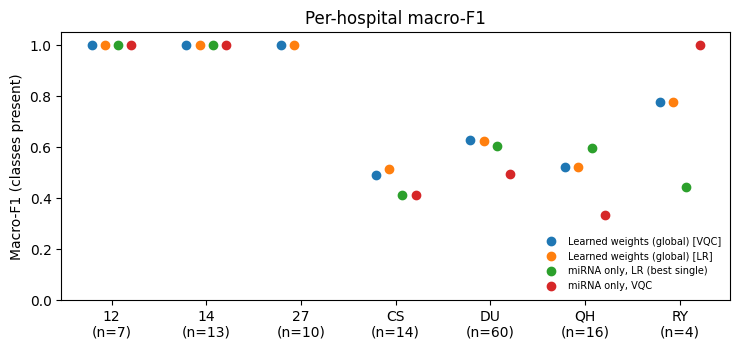

In [8]:
# ============================================================
# 7. TABLE A4 + FIGURE — PER-HOSPITAL RESULTS ON THE 7 TEST SITES
# macro-F1 is computed over the classes present at each site; small sites give unstable numbers (see n)
# ============================================================
def per_site(name, d):
    out = []
    for s in sorted(cohort.loc[d.index, "site"].unique()):
        ids = d.index[cohort.loc[d.index, "site"].values == s]
        yy, pp = y_of(ids), d.loc[ids].values.argmax(1)
        out.append({"model": name, "site": s, "n": len(ids), "classes_present": len(set(yy)),
                    "accuracy": accuracy_score(yy, pp), "macro_f1_present": macro_f1(yy, pp, labels=sorted(set(yy)))})
    return out


sel = [(n, d) for n, d in key_models()]
A4 = pd.DataFrame([r for n, d in sel for r in per_site(n, d)])
A4.to_csv(os.path.join(OUTPUT_DIR, "A4_per_hospital.csv"), index=False)
piv = A4.pivot(index="site", columns="model", values="macro_f1_present")
nn = A4[A4.model == sel[0][0]].set_index("site")["n"]
print("Macro-F1 per test hospital (classes present at that site):")
display(pd.concat([nn.rename("n (final model)"), piv.round(3)], axis=1))
spread = A4.groupby("model")["macro_f1_present"].agg(["mean", "std", "min", "max"]).round(3)
print("\nSpread across the 7 hospitals:"); display(spread)

fig, ax = plt.subplots(figsize=(7.5, 3.6))
sites = list(piv.index); x = np.arange(len(sites))
show = [c for c in [f"{FINAL[1]} [{FINAL[0]}]", "Learned weights (global) [LR]", "miRNA only, LR (best single)",
                    "miRNA only, VQC"] if c in piv.columns]
for j, col in enumerate(show):
    ax.plot(x + (j - (len(show) - 1) / 2) * 0.14, piv[col].values, "o", label=col, ms=6)
ax.set_xticks(x, [f"{s}\n(n={nn.get(s, 0)})" for s in sites]); ax.set_ylabel("Macro-F1 (classes present)")
ax.set_ylim(0, 1.05); ax.legend(fontsize=7, frameon=False, loc="lower right"); ax.set_title("Per-hospital macro-F1")
fig.tight_layout(); fig.savefig(os.path.join(OUTPUT_DIR, "figA4_per_hospital.png"), dpi=200); plt.show()

In [9]:
# ============================================================
# 8. TABLE A5 — FINAL MODEL: PERFORMANCE VS NUMBER OF AVAILABLE MODALITIES
# ============================================================
if (*FINAL, "test") in FUSION:
    d = FUSION[(*FINAL, "test")].loc[TEST]
    rows = []
    for k in sorted(cohort.loc[TEST, "n_mod"].unique()):
        ids = TEST[cohort.loc[TEST, "n_mod"].values == k]
        yy, pp = y_of(ids), d.loc[ids].values.argmax(1)
        rows.append({"modalities_available": int(k), "n_patients": len(ids), "accuracy": accuracy_score(yy, pp),
                     "macro_f1_present": macro_f1(yy, pp, labels=sorted(set(yy)))})
    A5 = pd.DataFrame(rows); A5.to_csv(os.path.join(OUTPUT_DIR, "A5_f1_vs_n_modalities.csv"), index=False)
    print(f"{FINAL[1]} [{FINAL[0]} base] on test patients grouped by how many of the six modalities they have:")
    display(A5.round(3))

Learned weights (global) [VQC base] on test patients grouped by how many of the six modalities they have:


,modalities_available,n_patients,accuracy,macro_f1_present
0,4,7,1.000,1.000
1,5,36,0.750,0.649
2,6,81,0.642,0.713


In [10]:
# ============================================================
# 9. TABLE A6 — QUANTUM VS CLASSICAL WITH MULTIPLE-COMPARISON CORRECTION (Holm and Bonferroni)
# Family 1 (fusion level, as in Fig 5.5): each fusion method on the VQC base vs the same method on the LR base,
#          plus meta-VQC vs meta-LR on the same 8 inputs (one per base).
# Family 2 (modality level): each modality's VQC vs logistic regression on exactly the same features (LRm).
# ============================================================
def pred(d, ids):
    return d.loc[ids].values.argmax(1)


fam1 = []
for meth in ["Mean", "Reliability-weighted", "Learned weights (global)", "Learned weights (per class)", "Stacking LR",
             "Meta-LR (same 8 inputs as meta-VQC)", "Meta-VQC (8 qubits)"]:
    if ("VQC", meth, "test") in FUSION and ("LR", meth, "test") in FUSION:
        fam1.append((f"VQC vs LR base — {meth}", pred(FUSION[("VQC", meth, "test")], TEST), pred(FUSION[("LR", meth, "test")], TEST), TEST))
for b in ["LR", "VQC"]:
    if (b, "Meta-VQC (8 qubits)", "test") in FUSION:
        fam1.append((f"Meta-VQC vs Meta-LR, same 8 inputs ({b} base)", pred(FUSION[(b, "Meta-VQC (8 qubits)", "test")], TEST),
                     pred(FUSION[(b, "Meta-LR (same 8 inputs as meta-VQC)", "test")], TEST), TEST))
fam2 = []
for m in MODALITIES:
    v, l = PROBS[(m, "VQC", "test")], PROBS[(m, "LRm", "test")]
    ids = v.index.intersection(l.index)
    fam2.append((f"{SHORT_M[m]}: VQC vs LR (same features)", pred(v, ids), pred(l, ids), ids))

rows = []
for fam_name, fam in [("1 fusion level", fam1), ("2 modality level", fam2)]:
    res = [(n, *paired_test(y_of(ids), a, b)) for n, a, b, ids in fam]
    if not res:
        continue
    p = [r[3] for r in res]; ph = holm(p); pb = np.minimum(1, np.array(p) * len(p))
    for (n, dlt, ci, pr), h, bo in zip(res, ph, pb):
        rows.append({"family": fam_name, "comparison": n, "delta_macro_f1": dlt, "ci_low": ci[0], "ci_high": ci[1],
                     "p_raw": pr, "p_holm": h, "p_bonferroni": bo, "significant_after_holm": h < 0.05})
A6 = pd.DataFrame(rows); A6.to_csv(os.path.join(OUTPUT_DIR, "A6_quantum_vs_classical_corrected.csv"), index=False)
print(f"Family 1 has {len(fam1)} comparisons" + ("" if len(fam1) == 9 else
      " (attach fusion_probs_all_methods.csv to get all 9 — stacking and meta-VQC need the fusion export)"))
print("Positive delta = quantum better. p from the paired bootstrap (two-sided, resolution 1/2000).")
display(A6.round(4))

Family 1 has 9 comparisons
Positive delta = quantum better. p from the paired bootstrap (two-sided, resolution 1/2000).


,family,comparison,delta_macro_f1,ci_low,ci_high,p_raw,p_holm,p_bonferroni,significant_after_holm
0,1 fusion level,VQC vs LR base — Mean,0.0445,-0.0113,0.1017,0.129,0.645,1.000,False
1,1 fusion level,VQC vs LR base — Reliability-weighted,0.0541,0.0013,0.1108,0.047,0.423,0.423,False
2,1 fusion level,VQC vs LR base — Learned weights (global),-0.0087,-0.0583,0.0378,0.745,1.000,1.000,False
3,1 fusion level,VQC vs LR base — Learned weights (per class),0.0111,-0.0315,0.0533,0.632,1.000,1.000,False
4,1 fusion level,VQC vs LR base — Stacking LR,0.0585,-0.0213,0.1431,0.156,0.645,1.000,False
5,1 fusion level,VQC vs LR base — Meta-LR (same 8 inputs as met...,0.0363,-0.0243,0.1006,0.254,0.762,1.000,False
6,1 fusion level,VQC vs LR base — Meta-VQC (8 qubits),-0.0733,-0.1573,0.0064,0.082,0.574,0.738,False
7,1 fusion level,"Meta-VQC vs Meta-LR, same 8 inputs (LR base)",0.0443,-0.0077,0.1001,0.092,0.574,0.828,False
8,1 fusion level,"Meta-VQC vs Meta-LR, same 8 inputs (VQC base)",-0.0653,-0.1324,0.0011,0.054,0.432,0.486,False
9,2 modality level,PROT: VQC vs LR (same features),-0.0093,-0.0909,0.0734,0.838,1.000,1.000,False


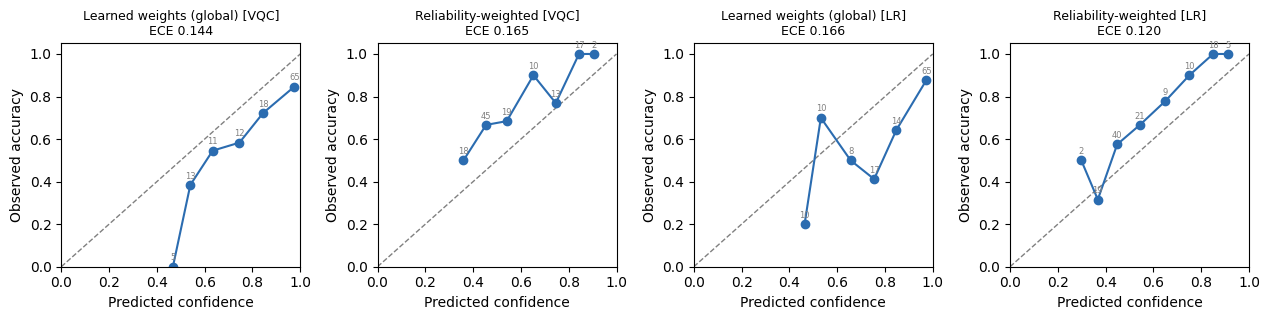

Numbers above the points = patients in that confidence bin. Points below the diagonal = over-confident.


In [11]:
# ============================================================
# 10. FIGURE A7 — RELIABILITY DIAGRAMS (calibration) FOR FOUR KEY MODELS
# ============================================================
def reliability(ax, y, P, title, n_bins=10):
    conf, pr = P.max(1), P.argmax(1); bins = np.linspace(0, 1, n_bins + 1); xs, ys, ns = [], [], []
    for lo, hi in zip(bins[:-1], bins[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            xs.append(conf[m].mean()); ys.append((pr[m] == y[m]).mean()); ns.append(m.sum())
    ax.plot([0, 1], [0, 1], ls="--", c="grey", lw=1)
    ax.plot(xs, ys, "o-", c="#2b6cb0")
    for a, b_, n in zip(xs, ys, ns):
        ax.text(a, b_ + 0.03, str(n), fontsize=6, ha="center", color="grey")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1.05); ax.set_title(f"{title}\nECE {ece_score(y, P):.3f}", fontsize=9)
    ax.set_xlabel("Predicted confidence"); ax.set_ylabel("Observed accuracy")


plots = [(n, d) for n, d in key_models() if not n.startswith("Mean")][:4]
fig, axes = plt.subplots(1, len(plots), figsize=(3.2 * len(plots), 3.3))
for ax, (n, d) in zip(np.atleast_1d(axes), plots):
    reliability(ax, y_of(d.index), d.values, n)
fig.tight_layout(); fig.savefig(os.path.join(OUTPUT_DIR, "figA7_reliability.png"), dpi=200); plt.show()
print("Numbers above the points = patients in that confidence bin. Points below the diagonal = over-confident.")

In [12]:
# ============================================================
# 11. TABLE A8 — PARAMETER EFFICIENCY: VQC vs CLASSICAL MODELS ON THE SAME TEST PATIENTS
# LR parameters = 4 classes x (features + 1 intercept). For hierarchical selectors the feature count is an upper bound.
# ============================================================
def lr_features(spec, m):
    if not isinstance(spec, (list, tuple)) or not spec:
        return np.nan
    kind = spec[0]
    if kind == "anova":
        return int(spec[1])
    if kind == "hier":
        return int(spec[1]) + int(spec[2])
    if kind == "drivers":
        return INFO[m]["vqc_qubits"]                       # SNV: the same 10 drivers + TMB
    if kind == "drivers+anova":
        return INFO[m]["vqc_qubits"] + int(spec[1])
    if kind == "all":
        return {"cnv": 68}.get(m, np.nan)
    return np.nan


rows = []
for m in MODALITIES:
    q = INFO[m]["vqc_qubits"]; fp = INFO[m].get("final_params", {})
    k_lr = lr_features(fp.get("sel__spec"), m)
    f = {mo: macro_f1(y_of(PROBS[(m, mo, "test")].index), PROBS[(m, mo, "test")].values.argmax(1)) for mo in ["VQC", "LRm", "LR"]}
    rows.append({"modality": SHORT_M[m], "qubits": q,
                 "VQC_params": INFO[m]["vqc_n_params"], "VQC_test_f1": f["VQC"],
                 "LR_same_features_params": 4 * (q + 1), "LR_same_features_test_f1": f["LRm"],
                 "LR_tuned_features": k_lr, "LR_tuned_params": 4 * (k_lr + 1) if k_lr == k_lr else np.nan,
                 "LR_tuned_test_f1": f["LR"], "LR_tuned_selector": str(fp.get("sel__spec")), "LR_tuned_C": fp.get("clf__C")})
A8 = pd.DataFrame(rows); A8.to_csv(os.path.join(OUTPUT_DIR, "A8_parameter_efficiency.csv"), index=False)
display(A8.round(3))
print("A fairer capacity-matched baseline (a small MLP with the same parameter count as each VQC) is added in Part C.")

,modality,qubits,VQC_params,VQC_test_f1,LR_same_features_params,LR_same_features_test_f1,LR_tuned_features,LR_tuned_params,LR_tuned_test_f1,LR_tuned_selector,LR_tuned_C
0,PROT,6,82,0.521,28,0.530,30,124,0.584,"['hier', 5, 25]",0.03
1,METH,4,48,0.561,20,0.575,100,404,0.705,"['hier', 10, 90]",0.01
2,GE,9,67,0.670,40,0.668,12,52,0.588,"['hier', 2, 10]",1.00
3,miRNA,8,84,0.614,36,0.615,100,404,0.694,"['anova', 100]",0.03
4,SNV,11,114,0.555,48,0.529,11,48,0.510,['drivers'],0.10
5,CNV,6,82,0.478,28,0.512,24,100,0.505,"['anova', 24]",0.30


A fairer capacity-matched baseline (a small MLP with the same parameter count as each VQC) is added in Part C.


In [13]:
# ============================================================
# 12. SUMMARY LINES FOR THE REPORT
# ============================================================
def line(s): print("•", s)


if (*FINAL, "test") in FUSION:
    d = FUSION[(*FINAL, "test")].loc[TEST]; r = all_metrics(y_te, d.values)
    line(f"Final model ({FINAL[1]}, {FINAL[0]} base), 124 test patients: macro-F1 {r['macro_f1']:.3f}, "
         f"macro ROC-AUC {r['macro_auc']:.3f}, macro PR-AUC {r['macro_prauc']:.3f}, MCC {r['mcc']:.3f}, "
         f"kappa {r['kappa']:.3f}, top-2 accuracy {r['top2_acc']:.3f}, log-loss {r['log_loss']:.3f}, "
         f"Brier {r['brier']:.3f}, ECE {r['ece']:.3f}.")
    line("Per-class ROC-AUC: " + ", ".join(f"{s} {r['auc_' + s]:.3f}" for s in SHORT) +
         " | PR-AUC: " + ", ".join(f"{s} {r['prauc_' + s]:.3f}" for s in SHORT))
    line("Sensitivity / specificity: " + ", ".join(f"{s} {r['sens_' + s]:.2f}/{r['spec_' + s]:.2f}" for s in SHORT))
    s_ = A4[A4.model == f"{FINAL[1]} [{FINAL[0]}]"]["macro_f1_present"]
    line(f"Across the 7 test hospitals the final model's macro-F1 ranged {s_.min():.3f}–{s_.max():.3f} "
         f"(mean {s_.mean():.3f}, SD {s_.std():.3f}).")
if len(A6):
    f1 = A6[A6.family.str.startswith("1")]
    line(f"Quantum vs classical (fusion level, {len(f1)} tests): {int((f1.p_raw < 0.05).sum())} significant before "
         f"correction, {int(f1.significant_after_holm.sum())} after Holm correction.")
    f2 = A6[A6.family.str.startswith("2")]
    line(f"Quantum vs classical (modality level, {len(f2)} tests): {int((f2.p_raw < 0.05).sum())} significant before "
         f"correction, {int(f2.significant_after_holm.sum())} after Holm correction.")
print("\nAll tables and figures saved in", OUTPUT_DIR, ":", sorted(os.listdir(OUTPUT_DIR)))

• Final model (Learned weights (global), VQC base), 124 test patients: macro-F1 0.698, macro ROC-AUC 0.883, macro PR-AUC 0.732, MCC 0.594, kappa 0.590, top-2 accuracy 0.895, log-loss 0.934, Brier 0.431, ECE 0.144.
• Per-class ROC-AUC: Astro 0.855, GBM 1.000, Mixed 0.786, Oligo 0.891 | PR-AUC: Astro 0.670, GBM 1.000, Mixed 0.622, Oligo 0.637
• Sensitivity / specificity: Astro 0.71/0.82, GBM 1.00/0.99, Mixed 0.42/0.87, Oligo 0.73/0.90
• Across the 7 test hospitals the final model's macro-F1 ranged 0.489–1.000 (mean 0.774, SD 0.231).
• Quantum vs classical (fusion level, 9 tests): 1 significant before correction, 0 after Holm correction.
• Quantum vs classical (modality level, 6 tests): 0 significant before correction, 0 after Holm correction.

All tables and figures saved in /kaggle/working/partA : ['A1_all_metrics_test.csv', 'A2_key_models_ci.csv', 'A3_robustness.csv', 'A4_per_hospital.csv', 'A5_f1_vs_n_modalities.csv', 'A6_quantum_vs_classical_corrected.csv', 'A8_parameter_efficiency.c

In [14]:
# ============================================================
# PAPER FIGURES THAT NEED PATIENT-LEVEL DATA
# Paste this as the LAST cell of notebook 08 (Part A metrics) and run it after all other cells.
# It only reads variables that notebook 08 already has in memory (cohort, PROBS, FUSION, TEST, CLASSES,
# MODALITIES, y_of, OUTPUT_DIR). Nothing is retrained. Run time: a few seconds.
# Output: OUTPUT_DIR/paper_figs/fig_sites.pdf, fig_upset.pdf, fig_roc.pdf, fig_reliability.pdf
# Download the four PDFs and upload them to the Overleaf project's figs/ folder (same names).
# ============================================================
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

FIG = os.path.join(OUTPUT_DIR, "paper_figs"); os.makedirs(FIG, exist_ok=True)
plt.rcParams.update({"font.family": "serif", "font.size": 8, "axes.titlesize": 8, "axes.labelsize": 8,
                     "xtick.labelsize": 7, "ytick.labelsize": 7, "legend.fontsize": 7,
                     "axes.spines.top": False, "axes.spines.right": False, "savefig.bbox": "tight", "pdf.fonttype": 42})
C1, CW = 3.5, 7.16
SHORT = {"astrocytoma": "Astro.", "glioblastoma": "GBM", "mixed_glioma": "Mixed", "oligodendroglioma": "Oligo."}
TEST_SET = set(TEST)
TRAIN = [p for p in cohort.index if p not in TEST_SET]
site_col = next(c for c in ["site", "TSS", "tss", "hospital"] if c in cohort.columns)
sub_col = next(c for c in ["subtype", "label", "y"] if c in cohort.columns)

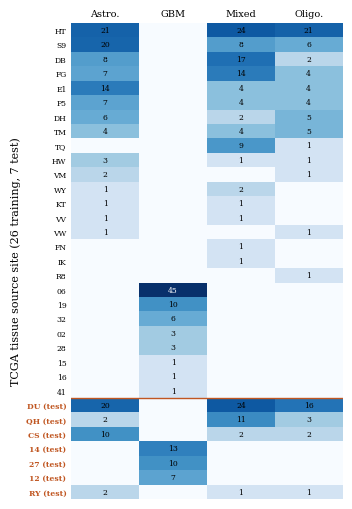

sites: 33 | GBM-only sites: 11


In [15]:
# ---------- 1. hospitals x subtypes heatmap, test sites marked (comment 31) ----------
tab = pd.crosstab(cohort[site_col], cohort[sub_col]).reindex(columns=[c for c in CLASSES if c in cohort[sub_col].unique()])
is_test = pd.Series({s: s in set(cohort.loc[list(TEST_SET), site_col]) for s in tab.index})
order = sorted(tab.index[~is_test.values], key=lambda s: (tab.loc[s, CLASSES[1]] == tab.loc[s].sum(), -tab.loc[s].sum()))
order += sorted(tab.index[is_test.values], key=lambda s: -tab.loc[s].sum())
tab = tab.loc[order]
fig, ax = plt.subplots(figsize=(C1, 0.16 * len(tab) + 0.9))
im = ax.imshow(np.log1p(tab.values), cmap="Blues", aspect="auto")
for i in range(tab.shape[0]):
    for j in range(tab.shape[1]):
        v = tab.values[i, j]
        if v: ax.text(j, i, str(v), ha="center", va="center", fontsize=5.5, color="white" if v > 25 else "black")
ax.set_xticks(range(tab.shape[1]), [SHORT.get(c, c) for c in tab.columns])
ax.set_yticks(range(len(tab)), [f"{s} (test)" if is_test[s] else s for s in tab.index], fontsize=5.5)
for t, s in zip(ax.get_yticklabels(), tab.index):
    if is_test[s]: t.set_color("#c05621"); t.set_fontweight("bold")
ntr = int((~is_test).sum()); ax.axhline(ntr - 0.5, color="#c05621", lw=1)
ax.xaxis.tick_top(); ax.tick_params(length=0)
for sp in ax.spines.values(): sp.set_visible(False)
ax.set_ylabel(f"TCGA tissue source site ({ntr} training, {len(tab) - ntr} test)")
fig.savefig(os.path.join(FIG, "fig_sites.pdf")); plt.show()
print("sites:", len(tab), "| GBM-only sites:", int((tab[CLASSES[1]] == tab.sum(axis=1)).sum()))


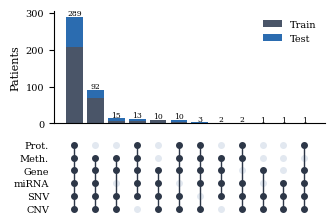

split   train  test
row_0              
111111    208    81
011111     70    22
011011      8     7
111110      8     5
001111     10     0
111011      4     6
111101      2     1
011110      2     0
110111      1     1
001011      1     0
000111      1     0
101111      0     1


In [16]:
# ---------- 2. modality availability patterns (UpSet-style, comment 22) ----------
def present(m):
    ids = set()
    for st in ["oof", "test"]:
        d = PROBS.get((m, "LR", st))
        if d is not None: ids |= set(d.dropna().index)
    return ids
PRES = {m: present(m) for m in MODALITIES}
pat = pd.DataFrame({m: [p in PRES[m] for p in cohort.index] for m in MODALITIES}, index=cohort.index)
pat["split"] = ["test" if p in TEST_SET else "train" for p in pat.index]
key = pat[MODALITIES].apply(lambda r: "".join("1" if v else "0" for v in r), axis=1)
cnt = pd.crosstab(key, pat["split"]).reindex(columns=["train", "test"]).fillna(0).astype(int)
cnt = cnt.loc[cnt.sum(axis=1).sort_values(ascending=False).index].head(12)   # 12 most common patterns
fig, (a1, a2) = plt.subplots(2, 1, figsize=(C1, 2.6), sharex=True, gridspec_kw={"height_ratios": [1.6, 1]})
x = np.arange(len(cnt))
a1.bar(x, cnt["train"], color="#4a5568", label="Train"); a1.bar(x, cnt["test"], bottom=cnt["train"], color="#2b6cb0", label="Test")
for i, (tr, te) in enumerate(cnt.values): a1.text(i, tr + te + 3, str(tr + te), ha="center", fontsize=5.5)
a1.set_ylabel("Patients"); a1.legend(frameon=False)
names = [{"proteomics": "Prot.", "methylation": "Meth.", "gene_expression": "Gene", "mirna": "miRNA", "snv": "SNV", "cnv": "CNV"}.get(m, m) for m in MODALITIES]
for i, k in enumerate(cnt.index):
    for j, b in enumerate(k):
        a2.plot(i, j, "o", color="#2d3748" if b == "1" else "#e2e8f0", ms=4)
    on = [j for j, b in enumerate(k) if b == "1"]
    if on: a2.plot([i, i], [min(on), max(on)], color="#2d3748", lw=1)
a2.set_yticks(range(len(MODALITIES)), names); a2.invert_yaxis(); a2.set_xticks([])
for sp in ["left", "bottom"]: a2.spines[sp].set_visible(False)
a2.tick_params(length=0)
fig.savefig(os.path.join(FIG, "fig_upset.pdf")); plt.show(); print(cnt)

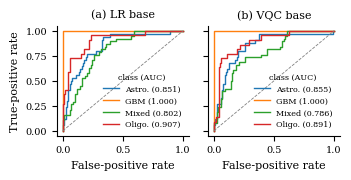

In [17]:
# ---------- 3. one-vs-rest ROC curves of the two primary pools (comment 71) ----------
fig, axs = plt.subplots(1, 2, figsize=(C1, 1.85), sharey=True)
y_te = y_of(TEST)
for ax, base in zip(axs, ["LR", "VQC"]):
    P = FUSION[(base, "Learned weights (global)", "test")].loc[TEST].values
    for k, c in enumerate(CLASSES):
        fpr, tpr, _ = roc_curve((y_te == k).astype(int), P[:, k])
        ax.plot(fpr, tpr, lw=1, label=f"{SHORT.get(c, c)} ({roc_auc_score((y_te == k).astype(int), P[:, k]):.3f})")
    ax.plot([0, 1], [0, 1], ls="--", color="grey", lw=0.6)
    ax.set_title(f"{'(a)' if base == 'LR' else '(b)'} {base} base"); ax.set_xlabel("False-positive rate")
    ax.legend(frameon=False, fontsize=5.8, loc="lower right", title="class (AUC)", title_fontsize=5.8)
axs[0].set_ylabel("True-positive rate")
fig.tight_layout(); fig.savefig(os.path.join(FIG, "fig_roc.pdf")); plt.show()

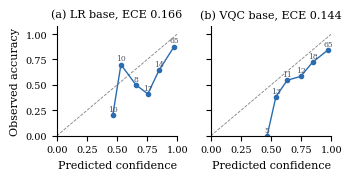

Saved: ['fig_reliability.pdf', 'fig_roc.pdf', 'fig_sites.pdf', 'fig_upset.pdf']


In [18]:
# ---------- 4. reliability diagrams of the two primary pools (comment 71) ----------
fig, axs = plt.subplots(1, 2, figsize=(C1, 1.85), sharey=True)
for ax, base in zip(axs, ["LR", "VQC"]):
    P = FUSION[(base, "Learned weights (global)", "test")].loc[TEST].values
    conf, pr = P.max(1), P.argmax(1); bins = np.linspace(0, 1, 11); xs, ys, ns = [], [], []
    for lo, hi in zip(bins[:-1], bins[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any(): xs.append(conf[m].mean()); ys.append((pr[m] == y_te[m]).mean()); ns.append(int(m.sum()))
    ax.plot([0, 1], [0, 1], ls="--", color="grey", lw=0.6); ax.plot(xs, ys, "o-", color="#2b6cb0", ms=3, lw=1)
    for a, b, n in zip(xs, ys, ns): ax.text(a, b + 0.04, str(n), fontsize=5.5, ha="center", color="#4a5568")
    ece = sum(n / len(conf) * abs(b - a) for a, b, n in zip(xs, ys, ns))
    ax.set_title(f"{'(a)' if base == 'LR' else '(b)'} {base} base, ECE {ece:.3f}"); ax.set_xlabel("Predicted confidence")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1.08)
axs[0].set_ylabel("Observed accuracy")
fig.tight_layout(); fig.savefig(os.path.join(FIG, "fig_reliability.pdf")); plt.show()
print("Saved:", sorted(os.listdir(FIG)))